In [2]:
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\Game Centar\Desktop\Python projects\Germany Data Jobs Analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df_DA_DE = df[(df['job_country'] == 'Germany') & (df['job_title_short'] == 'Data Analyst')]

In [4]:
df_DA_DE['job_location'].value_counts().head(10)

job_location
Berlin, Germany        935
Munich, Germany        634
Germany                613
Hamburg, Germany       521
Frankfurt, Germany     388
Düsseldorf, Germany    301
Anywhere               274
Cologne, Germany       250
Stuttgart, Germany     211
Hanover, Germany       113
Name: count, dtype: int64

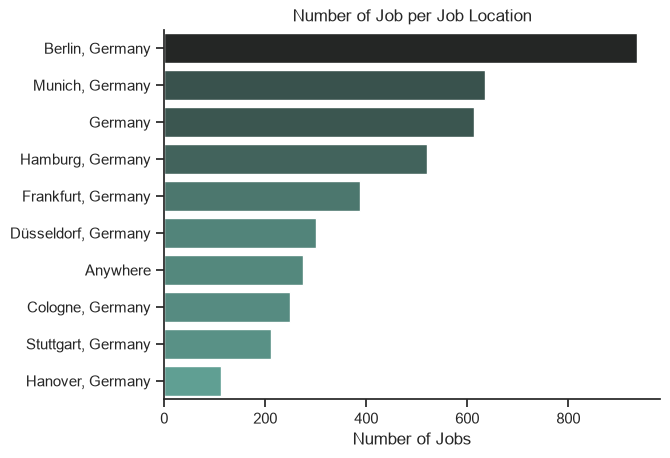

In [5]:
df_for_plot = df_DA_DE['job_location'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_for_plot, x='count', y='job_location', hue='count', palette='dark:#5A9_r', legend=False)
sns.despine()
plt.title('Number of Job per Job Location')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()


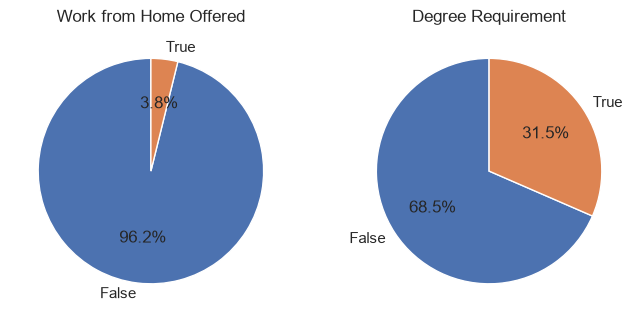

In [6]:
dict_column = {
    'job_work_from_home': 'Work from Home Offered',
    'job_no_degree_mention': 'Degree Requirement'
}

fig, ax = plt.subplots(1, 2)
fig.set_size_inches((8, 5))

for i, (column, title) in enumerate(dict_column.items()):
    ax[i].pie(df_DA_DE[column].value_counts(), labels=['False', 'True'], autopct='%1.1f%%', startangle=90)
    ax[i].set_title(title)

plt.show()

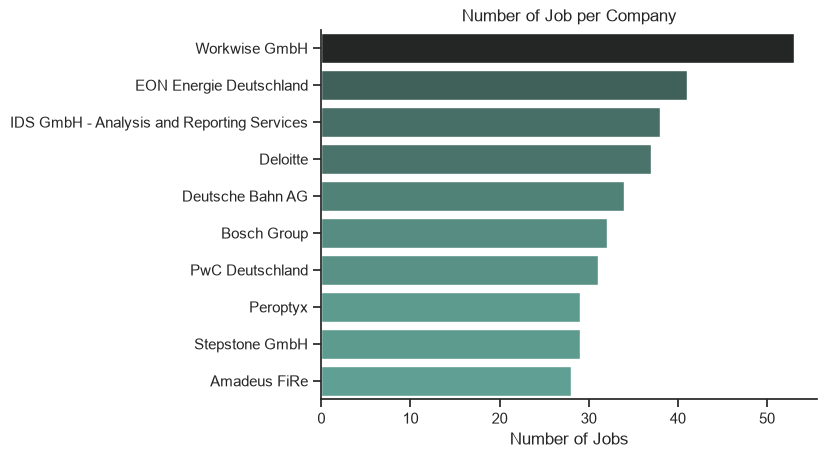

In [7]:
df_for_plot = df_DA_DE['company_name'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_for_plot, x='count', y='company_name', hue='count', palette='dark:#5A9_r', legend=False)
sns.despine()
plt.title('Number of Job per Company')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()
